# 2. O que os chamados do 156 dizem sobre os serviços urbanos do Recife

Cinco perguntas de gestão guiam este notebook:

1. Onde está a demanda: quais serviços e quais bairros?
2. A demanda está crescendo, e quando ela chega?
3. Quanto tempo cada tipo de serviço leva para ser atendido?
4. Alguma região da cidade espera mais pelo mesmo serviço?
5. Quanto da fila em aberto está parada?

Os dados vêm do PostgreSQL carregado pelo pipeline, já limpos (ver [01_data_cleaning.ipynb](01_data_cleaning.ipynb)). As consultas principais estão versionadas em [`sql/analyses`](../sql/analyses).

In [1]:
import pandas as pd
from sqlalchemy import text

from src.analysis.charts import plot_monthly_trend, plot_resolution_heatmap, plot_volume_by_group
from src.config import DOCS_DIR, SQL_DIR
from src.db.load import get_engine

engine = get_engine()
images = DOCS_DIR / "img"


def query(sql: str) -> pd.DataFrame:
    with engine.connect() as connection:
        return pd.read_sql(text(sql), connection)


# Runs a versioned query by its number, e.g. run_sql("01") reads sql/analyses/01_*.sql
def run_sql(number: str) -> pd.DataFrame:
    path = next((SQL_DIR / "analyses").glob(f"{number}_*.sql"))
    return query(path.read_text(encoding="utf-8"))


query("""
    SELECT COUNT(*) AS tickets,
           ROUND(100.0 * AVG((status = 'ATENDIDA')::int), 1) AS pct_resolved,
           MIN(opened_on) AS first_opened,
           MAX(status_updated_on) AS status_as_of
    FROM tickets
""")

,tickets,pct_resolved,first_opened,status_as_of
0,204408,77.2,2024-01-01,2025-12-31


## 1. Onde está a demanda?

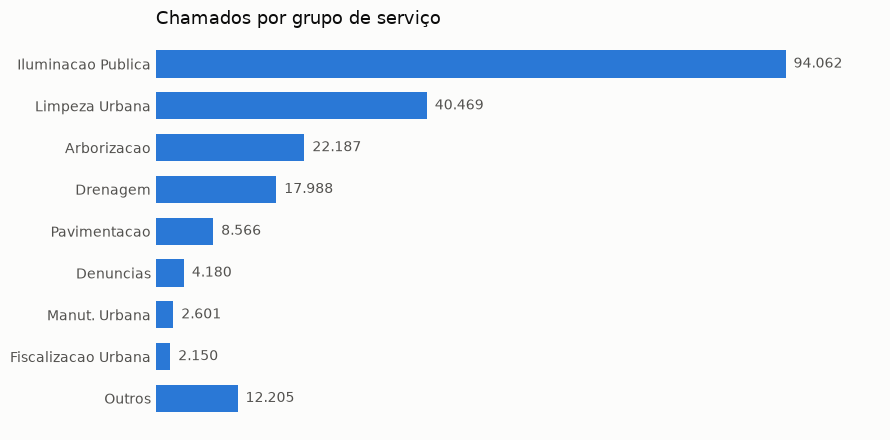

In [2]:
groups = run_sql("01")
plot_volume_by_group(groups, images / "volume_by_group.png")

Iluminação pública é quase metade de tudo o que chega ao 156 (46%), seguida de limpeza urbana (20%) e arborização (11%).

Hipótese H1: os 10 serviços mais pedidos somam pelo menos 70% dos chamados. Se for verdade, agir sobre poucos serviços alivia a central de forma desproporcional.

In [3]:
services = run_sql("02")
services.head(10)[["service_name", "group_name", "tickets", "pct_total", "cumulative_pct"]]

,service_name,group_name,tickets,pct_total,cumulative_pct
0,MANUTENCAO EM LAMPADA APAGADA,ILUMINACAO PUBLICA,72716,35.6,35.6
1,REMOCAO DE ENTULHOS,LIMPEZA URBANA,23374,11.4,47.0
2,ACENDER CIRCUITO,ILUMINACAO PUBLICA,14644,7.2,54.2
3,VISTORIA DE ARVORES,ARBORIZACAO,13902,6.8,61.0
4,CAPINACAO EM VIA PAVIMENTADA,LIMPEZA URBANA,9863,4.8,65.8
5,LIMPEZA DE GALERIAS E VALETAS,DRENAGEM,7470,3.7,69.5
6,PODA DE ARVORES,ARBORIZACAO,6189,3.0,72.5
7,"REPOSICAO TAMPA DE POCO, GALERIAS,MEIO FIO E P...",DRENAGEM,3959,1.9,74.4
8,CAPINACAO EM VIA NAO PAVIMENTADA,LIMPEZA URBANA,3928,1.9,76.3
9,"DENUNCIA DE ARBOVIROSES (DENGUE, CHIKUNGUNYA, ...",DENUNCIAS,3302,1.6,78.0


H1 confirmada: 10 dos 108 serviços somam 78% dos chamados, e "lâmpada apagada" sozinho responde por 35,6%. Manutenção preventiva da iluminação, ou um canal de autoatendimento só para esse pedido, é a ação com maior efeito isolado sobre o volume da central.

In [4]:
run_sql("04")

,city_rank,neighborhood_name,rpa,rank_in_rpa,tickets,pct_resolved
0,1,BOA VIAGEM,6,1,12789,76.2
1,2,SANTO AMARO,1,1,8421,82.0
2,3,IMBIRIBEIRA,6,2,7468,73.4
3,4,COHAB IBURA DE CIMA,6,3,7272,74.0
4,5,VARZEA,4,1,7115,74.4
5,6,IPUTINGA,4,2,7021,75.6
6,7,CORDEIRO,4,3,6590,72.0
7,8,AFOGADOS,5,1,5717,71.2
8,9,IBURA,6,4,5348,73.4
9,10,BOA VISTA,1,2,5167,89.0


Boa Viagem lidera em volume, mas volume absoluto acompanha o tamanho de cada bairro, e sem população por bairro não dá para dizer que um é mais demandante que outro. O que diferencia os bairros é a parcela já atendida: entre os 15 maiores, vai de 70% em San Martin a 89% em Boa Vista. Isso pode vir do tipo de serviço pedido em cada lugar ou da região; as seções 3 e 4 separam esses dois efeitos.

## 2. A demanda está crescendo, e quando ela chega?

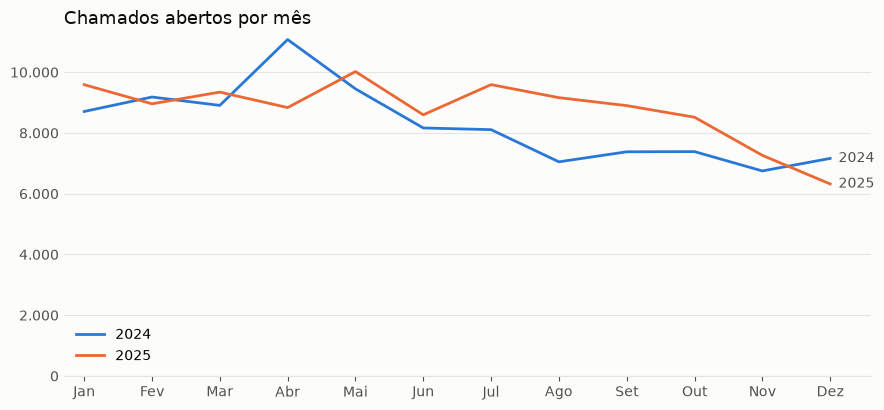

In [5]:
monthly = run_sql("03")
plot_monthly_trend(monthly, images / "monthly_trend.png")

In [6]:
yearly = monthly.groupby(pd.to_datetime(monthly["month"]).dt.year)["tickets"].sum()
pd.DataFrame({"tickets": yearly, "change_pct": yearly.pct_change().mul(100).round(1)})

,tickets,change_pct
month,,
2024,99315,NaN
2025,105093,5.8


Em 2025 foram 105.093 chamados, 5,8% a mais que em 2024. O aumento se concentra de julho a outubro, de 15% a 30% acima dos mesmos meses de 2024. O primeiro semestre ficou próximo do ano anterior, exceto abril, porque abril de 2024 foi o pico isolado da série (11.074 chamados).

In [7]:
run_sql("08")[["weekday", "tickets", "avg_tickets_per_day"]]

,weekday,tickets,avg_tickets_per_day
0,Segunda,34922,332.6
1,Terça,40140,382.3
2,Quarta,38114,363.0
3,Quinta,37143,357.1
4,Sexta,33092,318.2
5,Sábado,11379,109.4
6,Domingo,9618,92.5


Dias úteis recebem de 320 a 380 chamados por dia; sábados e domingos, cerca de 100. Triagem e despacho podem ser dimensionados pelo calendário útil, com plantão reduzido no fim de semana.

## 3. Quanto tempo cada tipo de serviço leva?

Medido nos chamados já atendidos, como os dias entre a abertura e a última mudança de situação.

In [8]:
run_sql("05")

,group_name,resolved_tickets,median_days,p90_days,pct_within_7_days
0,ESCADARIA,192,225.0,449.6,1.0
1,ACAO EDUCATIVA,303,169.0,406.6,1.0
2,MACRODRENAGEM,226,129.0,270.5,0.9
3,DRENAGEM,4026,47.0,259.0,35.7
4,PLANEJAMENTO DE LIMPEZA URBANA,132,42.5,211.1,17.4
5,PAVIMENTACAO,1987,31.0,158.0,22.2
6,PRACAS,673,21.0,321.4,4.6
7,DENUNCIAS,3289,20.0,46.0,14.4
8,ARBORIZACAO,10548,19.0,126.0,23.5
9,LIMPEZA URBANA,39008,12.0,118.0,36.8


O tipo de serviço define a espera. Iluminação pública tem mediana de 2 dias e 94% dos chamados atendidos em até uma semana. Drenagem tem mediana de 47 dias, pavimentação 31 e arborização 19. Escadarias (225 dias) e macrodrenagem (129) são obras, não reparos, e têm poucos casos.

Esses números olham só para quem já foi atendido. Em serviços com muita fila a espera real é maior, como mostra a seção 5.

## 4. Alguma região espera mais pelo mesmo serviço?

Hipótese H2: dentro de um mesmo grupo de serviço, a região (RPA) mais lenta não leva mais que o dobro da mais rápida. Se for falsa, há um problema de capacidade ou de contrato regional que a gestão pode atacar diretamente. A comparação usa os quatro maiores grupos e só conta como desigual uma diferença acima de 2 vezes e de mais de 7 dias, para que 1 contra 2 dias não pese.

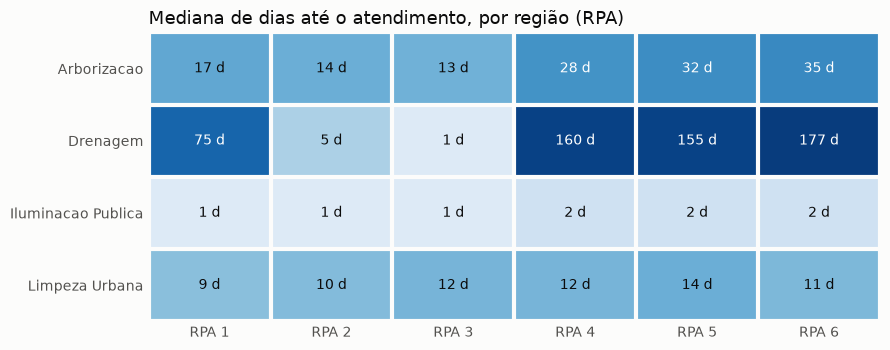

In [9]:
by_rpa = run_sql("06")
plot_resolution_heatmap(by_rpa, images / "resolution_by_rpa.png")

In [10]:
gaps = by_rpa.groupby("group_name")["median_days"].agg(fastest="min", slowest="max")
gaps["ratio"] = (gaps["slowest"] / gaps["fastest"].clip(lower=1)).round(1)
gaps["unequal"] = (gaps["ratio"] > 2) & (gaps["slowest"] - gaps["fastest"] > 7)
gaps.sort_values("ratio", ascending=False)

,fastest,slowest,ratio,unequal
group_name,,,,
DRENAGEM,1.0,177.0,177.0,True
ARBORIZACAO,13.0,35.0,2.7,True
ILUMINACAO PUBLICA,1.0,2.0,2.0,False
LIMPEZA URBANA,9.0,14.0,1.6,False


H2 refutada para drenagem e arborização, confirmada para iluminação e limpeza urbana. Em drenagem, as RPAs 4, 5 e 6 (oeste, sudoeste e sul) esperam de 155 a 177 dias, contra 1 a 5 dias nas RPAs 2 e 3.

Antes de atribuir isso à região, falta descartar uma explicação mais simples: cada região pode pedir serviços diferentes dentro de drenagem. O teste é olhar um único serviço em todas as RPAs.

In [11]:
query("""
    SELECT n.rpa,
           COUNT(*) AS resolved_tickets,
           PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY t.days_to_last_update) AS median_days
    FROM tickets AS t
    JOIN services AS s USING (service_code)
    JOIN neighborhoods AS n USING (neighborhood_id)
    WHERE t.status = 'ATENDIDA' AND s.service_name = 'LIMPEZA DE GALERIAS E VALETAS'
    GROUP BY n.rpa
    ORDER BY n.rpa
""")

,rpa,resolved_tickets,median_days
0,1,367,69.0
1,2,471,53.0
2,3,464,35.0
3,4,160,170.0
4,5,252,154.5
5,6,203,197.0


Mesmo serviço, esperas muito diferentes: limpeza de galerias leva de 35 a 69 dias nas RPAs 1 a 3 e de 155 a 197 dias nas RPAs 4 a 6. A diferença não vem da mistura de serviços, vem da região. É um sinal forte de capacidade ou contrato regional em drenagem, a ser levado às equipes das RPAs 4 a 6.

## 5. Quanto da fila em aberto está parada?

Idade dos chamados ainda não atendidos, contada até a data mais recente dos dados.

In [12]:
run_sql("07")

,group_name,open_tickets,up_to_30_days,from_31_to_180_days,over_180_days,pct_over_180_days
0,DRENAGEM,13962,424,3017,10521,75.4
1,ARBORIZACAO,11639,369,2370,8900,76.5
2,PAVIMENTACAO,6579,205,2302,4072,61.9
3,MANUT. URBANA,2585,93,641,1851,71.6
4,ILUMINACAO PUBLICA,1743,164,785,794,45.6
5,ESCADARIA,1539,23,246,1270,82.5
6,LIMPEZA URBANA,1461,324,613,524,35.9
7,PROJETOS,1348,56,464,828,61.4
8,PRACAS,1344,39,338,967,71.9
9,MACRODRENAGEM,1256,47,226,983,78.3


Drenagem tem 13.961 chamados em aberto (78% de todos os pedidos de drenagem do período), três quartos deles há mais de 180 dias. Arborização segue o mesmo padrão, com 11.638 em aberto. Iluminação e limpeza, os serviços de maior volume, têm fila pequena perto do que recebem (menos de 2% e 4% dos pedidos).

Uma fila desse tamanho e dessa idade mistura duas coisas: pendência real e chamado resolvido sem baixa no sistema. Uma revisão dos chamados com mais de 180 dias separaria as duas e daria à gestão o tamanho real do passivo.

O resumo das conclusões está em [`docs/analises.md`](../docs/analises.md).